<a href="https://colab.research.google.com/github/Jabbiks/ML/blob/main/%D0%9B%D0%A0_10_%D0%90%D0%B2%D1%80%D0%B0%D0%BC%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Авраменко Кирило  
**Група:** ФІТ 3-10  
**Дата:** 20.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("x_train shape:", x_train.shape, "| y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape, "| y_test shape:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train shape: (60000, 28, 28) | y_train shape: (60000,)
x_test shape: (10000, 28, 28) | y_test shape: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

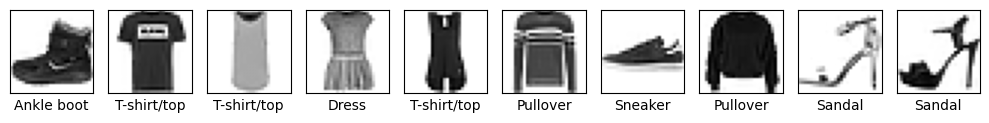

In [3]:
plt.figure(figsize=(10, 10))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train = (x_train / 255.0).astype("float32")
x_test = (x_test / 255.0).astype("float32")

print("x_train діапазон:", x_train.min(), "—", x_train.max(), "| dtype:", x_train.dtype)
print("x_test діапазон:", x_test.min(), "—", x_test.max(), "| dtype:", x_test.dtype)

x_train діапазон: 0.0 — 1.0 | dtype: float32
x_test діапазон: 0.0 — 1.0 | dtype: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
model = models.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Кількість нейронів (256 $\rightarrow$ 64 $\rightarrow$ 10): після розгортання зображення $28 \times 28$ у вектор довжиною 784 ознаки, перший прихований шар на 256 нейронів виділяє базові комбінації ознак, другий на 64 нейрони стискає та узагальнює їх, а вихідний шар на 10 нейронів із функцією softmax формує ймовірності належності до кожного з 10 класів. Така пірамідальна структура зменшує ризик перенавчання.   

Dropout (0.3): випадкове вимкнення 30% нейронів під час навчання запобігає їхній надмірній адаптації під конкретні приклади навчальної вибірки та покращує узагальнювальну здатність моделі.   

Швидкість навчання (learning_rate = 3e-4): менший крок за стандартний (1e-3) забезпечує більш плавну та стабільну збіжність оптимізатора Adam без різких стрибків функції втрат, а в поєднанні з ReduceLROnPlateau дозволяє точно налаштувати ваги на пізніх епохах.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
cb = [
    EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

history = model.fit(
    x_train, y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.1,
    callbacks=cb,
    verbose=1
)

Epoch 1/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7038 - loss: 0.8530 - val_accuracy: 0.8265 - val_loss: 0.4957 - learning_rate: 3.0000e-04
Epoch 2/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8158 - loss: 0.5338 - val_accuracy: 0.8437 - val_loss: 0.4306 - learning_rate: 3.0000e-04
Epoch 3/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8379 - loss: 0.4648 - val_accuracy: 0.8597 - val_loss: 0.3902 - learning_rate: 3.0000e-04
Epoch 4/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8482 - loss: 0.4311 - val_accuracy: 0.8647 - val_loss: 0.3724 - learning_rate: 3.0000e-04
Epoch 5/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8581 - loss: 0.4022 - val_accuracy: 0.8668 - val_loss: 0.3554 - learning_rate: 3.0000e-04
Epoch 6/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8643 - loss: 0.3850 - val_accuracy: 0.8697 - val_loss: 0.3502 - learning_rate: 3.0000e-04
Epoch 7/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy:

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()
print("Загальна кількість шарів:", len(model.layers))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 654,176 (2.50 MB)

 Trainable params: 218,058 (851.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 436,118 (1.66 MB)

Загальна кількість шарів: 6


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
from google.colab import drive
drive.mount('/content/drive')
model.save('/content/drive/MyDrive/fashion_mnist_model.keras')

Mounted at /content/drive


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

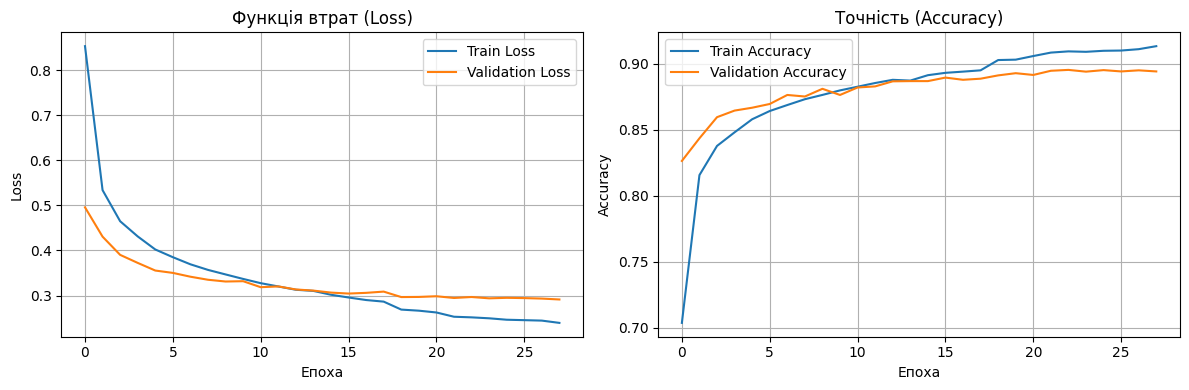

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Функція втрат (Loss)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Точність (Accuracy)')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print("Поріг 0.87 досягнуто:", test_acc >= 0.87)

predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(y_test, predicted_labels, target_names=class_names))

313/313 - 2s - 6ms/step - accuracy: 0.8890 - loss: 0.3187
Test loss: 0.3187
Test accuracy: 0.8890
Поріг 0.87 досягнуто: True
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.84      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.79      0.82      0.80      1000
       Dress       0.89      0.90      0.89      1000
        Coat       0.80      0.82      0.81      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.72      0.68      0.70      1000
     Sneaker       0.93      0.97      0.95      1000
         Bag       0.97      0.98      0.98      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

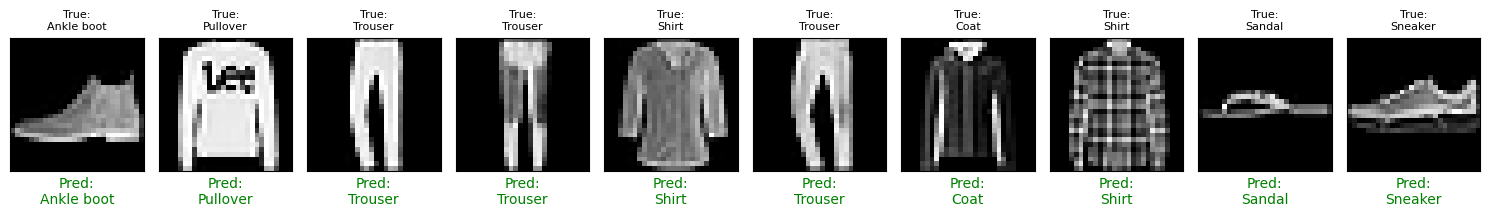

In [12]:
plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_test[i], cmap='gray')
    pred_label = class_names[predicted_labels[i]]
    true_label = class_names[y_test[i]]
    color = 'green' if predicted_labels[i] == y_test[i] else 'red'
    plt.xlabel(f"Pred:\n{pred_label}", color=color)
    plt.title(f"True:\n{true_label}", fontsize=8)

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

На тестовій вибірці базова модель досягла точності 0.8890 (88,90%) при втратах 0.3187, що успішно виконує встановлену вимогу щодо мінімальної точності (не нижче 0.87).   Згідно з класифікаційним звітом, найкраще модель розпізнає штани, сумки та взуття: Trouser (f1-score = 0.98), Bag (0.98), Sandal (0.97), Ankle boot (0.96) та Sneaker (0.95). Найбільша кількість помилок припадає на клас Shirt (precision = 0.72, recall = 0.68, f1-score = 0.70), а також на суміжні категорії верхнього одягу — Pullover (0.80), Coat (0.81) та T-shirt/top (0.84), оскільки на монохромних зображеннях $28 \times 28$ пікселів їхні контури й текстури дуже подібні.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [13]:
!pip install keras-tuner -q

from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.regularizers import l2
from keras_tuner.tuners import RandomSearch

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

x_train_full = (x_train_full / 255.0).astype("float32")
x_test = (x_test / 255.0).astype("float32")

# Відокремлюємо валідаційну вибірку від навчальної (x_test не використовується під час пошуку)
val_size = int(0.1 * len(x_train_full))
x_val, y_val = x_train_full[:val_size], y_train_full[:val_size]
x_tr, y_tr = x_train_full[val_size:], y_train_full[val_size:]

### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(Dense(
            units=hp.Int('units_' + str(i), min_value=32, max_value=512, step=32),
            activation='relu',
            kernel_regularizer=l2(0.001)
        ))
        model.add(Dropout(0.2))

    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(
            hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='tuner_logs',
    project_name='fashion_mnist_classification',
    overwrite=True
)

### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

tuner.search(
    x_tr, y_tr,
    epochs=50,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr]
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:", best_hps.values)

best_model = tuner.get_best_models(num_models=1)[0]
best_model.summary()

history_tuned = best_model.fit(
    x_tr, y_tr,
    epochs=50,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr]
)

Trial 3 Complete [00h 01m 55s]
val_accuracy: 0.8646666407585144

Best val_accuracy So Far: 0.8646666407585144
Total elapsed time: 00h 05m 14s
Найкращі гіперпараметри: {'num_layers': 1, 'units_0': 352, 'learning_rate': 0.001, 'units_1': 288, 'units_2': 416}


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 352)            │       276,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         3,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 279,850 (1.07 MB)

 Trainable params: 279,850 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8476 - loss: 0.5001 - val_accuracy: 0.8637 - val_loss: 0.4555 - learning_rate: 0.0010
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8492 - loss: 0.4976 - val_accuracy: 0.8522 - val_loss: 0.4875 - learning_rate: 0.0010
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8527 - loss: 0.4916 - val_accuracy: 0.8675 - val_loss: 0.4461 - learning_rate: 0.0010
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8510 - loss: 0.4949 - val_accuracy: 0.8552 - val_loss: 0.4773 - learning_rate: 0.0010
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.8519 - loss: 0.4925 - val_accuracy: 0.8713 - val_loss: 0.4463 - learning_rate: 0.0010
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8550 - loss: 0.4866 - val_accuracy: 0.8718 - val_loss: 0.4494 - learning_rate: 0.0010


### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

313/313 - 1s - 4ms/step - accuracy: 0.8573 - loss: 0.4797
Test accuracy (Keras Tuner): 0.8573
Test loss (Keras Tuner): 0.4797


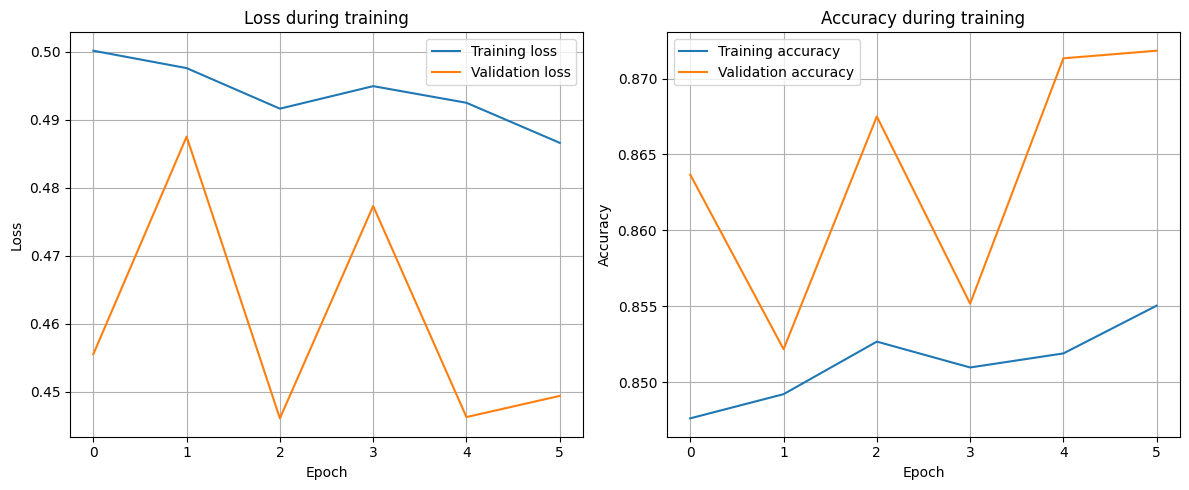

In [18]:
tuned_test_loss, tuned_test_acc = best_model.evaluate(x_test, y_test, verbose=2)
print(f"Test accuracy (Keras Tuner): {tuned_test_acc:.4f}")
print(f"Test loss (Keras Tuner): {tuned_test_loss:.4f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['loss'], label='Training loss')
plt.plot(history_tuned.history['val_loss'], label='Validation loss')
plt.title('Loss during training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['accuracy'], label='Training accuracy')
plt.plot(history_tuned.history['val_accuracy'], label='Validation accuracy')
plt.title('Accuracy during training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів |256.64  |352  |
| Швидкість навчання | 0.0003 (3e-4) | 0.001 (1e-3) |
| Точність на тестовій вибірці (accuracy) | 0.8890 | 0.8573 |
| Втрати на тестовій вибірці (loss) | 0.3187 | 0.4797 |
| Кількість епох навчання | 28 | 6 (донавчання після пошуку) |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. Чи досягнуто точності не нижче 0,87 у завданні 1?

Так, базова модель із двома прихованими шарами (256 і 64 нейрони), регуляризацією Dropout(0.3) та швидкістю навчання 0.0003 досягла на тестовій вибірці точності 0.8890 (втрати — 0.3187), що перевищує цільовий поріг 0.87.

2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?

Ні, у цьому експерименті модель після Keras Tuner показала нижчу точність (0.8573 проти 0.8890) і вищі втрати (0.4797 проти 0.3187). Це зумовлено малою кількістю спроб випадкового пошуку (max_trials = 3), вибором одного прихованого шару замість двошарової пірамідальної структури, а також використанням L2-регуляризації (l2(0.001)), яка додає штраф за величину ваг до функції втрат і обмежила здатність моделі донавчатися за 6 епох.   

3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?

Серед перевірених конфігурацій найкращою виявилася архітектура з 1 прихованим шаром на 352 нейрони та швидкістю навчання 0.001 (val_accuracy = 0.8647 під час пошуку). Результати відрізняються між запусками через стохастичність алгоритму RandomSearch (випадковий вибір комбінацій гіперпараметрів), випадкову початкову ініціалізацію ваг мережі, випадкове перемішування навчальних батчів і роботу шарів Dropout під час тренування.   

4. Які класи Fashion MNIST класифікувати найскладніше?

Найскладніше класифікувати категорію Shirt (f1-score = 0.70), а також візуально схожі категорії верхнього одягу — Pullover (0.80), Coat (0.81) та T-shirt/top (0.84). Через низьку роздільну здатність зображень ($28 \times 28$ пікселів у відтінках сірого) дрібні деталі комірів, застібок і рукавів зливаються, тому мережа найчастіше плутає ці класи між собою.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.